# Emometer 2: a group of SAE features per emotion

An upgrade of `1a_sae_hand_picked_features.ipynb`. Instead of one hand-picked feature per emotion, this notebook asks Neuronpedia which features fire on clearly emotional text, keeps the ones whose autointerp label is about that emotion, and tracks the **5 strongest** as a group.

- **Model and SAEs:** the same as `1a_sae_hand_picked_features.ipynb`: `llama3.1-8b` (Llama 3.1 8B base, open weights) with the Llama Scope 32k residual-stream SAEs.
- **Layers searched:** 12–27 of 32, the middle and middle-later layers.
- **Emotion:** set `EMOTION` below. Probe texts and label patterns are included for the four emotions EmoLex shares with the SAE side: `joy`, `sadness`, `anger` and `fear`.

**How the features are picked (step 1):**
1. Each probe text is run through Neuronpedia's search, one layer at a time. Each call returns the 99 features with the highest activation on the text (99 is the most the API allows). Features active on more than 1% of all tokens are skipped as too generic.
2. A feature's **score** is its peak activation on each probe divided by its own max activation (`maxActApprox`), capped at 1 and averaged over the probes (0 for a probe it wasn't in the top 99 for).
3. Only features whose autointerp label names the emotion are kept (`INCLUDE`), unless the label also names another emotion or an unrelated topic (`EXCLUDE`).
4. The best of those are run on a neutral control text. Any that fire there above 10% of their max are dropped.
5. The top `N_FEATURES` by score are used.

**Graphs (step 2):** the story is read from `data/stories/the-yellow-wallpaper.txt` and processed as in `1a_sae_hand_picked_features.ipynb` (chunks of about 900 characters, with requests cached under `.activation_cache/`). Each token's activation is divided by the feature's max activation, capped at 1 and averaged over 100-word windows, as in Figure 1 of `1a_sae_hand_picked_features.ipynb`. Figures 1–4 are saved to `outputs/figures/pilot2/`, so they don't overwrite the other notebooks' figures.

In [1]:
import bisect
import contextlib
import hashlib
import io
import json
import math
import os
import re
import sys
import threading
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import requests
from dotenv import load_dotenv
from neuronpedia.requests.activation_request import ActivationRequest
from neuronpedia.requests.base_request import NPRateLimitError

load_dotenv()

MODEL_ID = "llama3.1-8b"
SOURCE_SET = "llamascope-res-32k"
LAYERS = [f"{layer}-{SOURCE_SET}" for layer in range(12, 28)]  # middle and middle-later layers of 32

EMOTION = "joy"          # joy, sadness, anger or fear
N_FEATURES = 5
DENSITY_MAX = 0.01       # skip features active on more than 1% of all tokens
NEUTRAL_MAX = 0.10       # drop a feature whose activation on the neutral text exceeds 10% of its max

STORY_NAME = "The Yellow Wallpaper"
STORY_PATH = Path("data/stories/the-yellow-wallpaper.txt")
WINDOW_WORDS = 100
FIG_DATE = "Nov 13, 2026"

# Clearly emotional texts used to find the features. Several per emotion, so a feature that only
# reacts to one word or one situation scores lower than one that fires on all of them.
PROBES = {
    "joy": [
        "We won! Everyone was laughing and hugging, and I was so happy I could have danced all night.",
        "When she opened the door and saw all her friends shouting 'Surprise!', her face lit up with pure joy. It was the best birthday of her life.",
        "The baby giggled, and her grandfather beamed with delight. Nothing in the world could have made him happier than that little laugh.",
        "I got the job! I called my mom, and we were both cheering and crying happy tears. What a wonderful, glorious day.",
    ],
    "sadness": [
        "After the funeral the house felt empty. She sat on his side of the bed and cried until there were no tears left.",
        "He read the letter again. She wasn't coming back. He felt a heavy, hollow sorrow settle in his chest.",
        "The old dog didn't wake up this morning. The children wept quietly in the yard, too heartbroken to speak.",
        "I miss you so much. Every day without you is gray and lonely, and the grief never really goes away.",
    ],
    "anger": [
        "He slammed his fist on the table and shouted, 'How dare you lie to me!' His face was red with rage.",
        "She was furious. They had cheated her out of her pay, and she wanted to scream at every one of them.",
        "I am so angry I can't think straight. You broke your promise again, and I'm sick of your excuses!",
        "The crowd roared in outrage, hurling insults and shaking their fists at the corrupt officials.",
    ],
    "fear": [
        "Something was breathing in the dark behind her. She froze, terrified, her heart pounding in her ears.",
        "He was so scared he couldn't move. The footsteps came closer, and he knew whoever it was would find him.",
        "The children screamed in terror as the house shook and the walls began to crack.",
        "I'm afraid. I keep hearing noises at night, and I'm too frightened to open the door.",
    ],
}
NEUTRAL = (
    "The train leaves the central station at nine fifteen and arrives in the city just after eleven. "
    "Passengers can buy tickets at the counter or from the machines near the main entrance. The second "
    "carriage has tables and power outlets."
)

# A feature is kept only if its autointerp label matches INCLUDE and not EXCLUDE (whole words, any case).
_OTHER_TOPICS = r"histor\w*|politic\w*|legal|religio\w*|sport\w*"
INCLUDE = {
    "joy": r"happ\w*|joy\w*|delight\w*|cheer\w*|celebrat\w*|excite\w*|excitement|elat\w*|glad\w*|enjoy\w*|laugh\w*|bliss\w*|euphori\w*|jubila\w*",
    "sadness": r"sad\w*|grie\w*|mourn\w*|sorrow\w*|melanchol\w*|despair\w*|lonel\w*|heartbr\w*|weep\w*|crying|tears",
    "anger": r"anger|angry|rage|fury|furious|hostil\w*|resent\w*|frustrat\w*|annoy\w*|irritat\w*|outrage\w*",
    "fear": r"fear\w*|afraid|terror|terrif\w*|scare\w*|dread\w*|horror|fright\w*|panic\w*",
}
_OPPOSITE = {"joy": r"distress|negative", "sadness": "positive", "anger": "positive", "fear": "positive"}
# A label is excluded if it also names another emotion, the opposite valence or an unrelated topic.
EXCLUDE = {
    emotion: "|".join([p for other, p in INCLUDE.items() if other != emotion] + [_OPPOSITE[emotion], _OTHER_TOPICS])
    for emotion in INCLUDE
}

# Story requests, as in 1a_sae_hand_picked_features.ipynb
MAX_CHUNK_CHARS = 900
MIN_CHUNK_CHARS = 60
MAX_CONCURRENT = 8
RETRIES = 4
TIMEOUT = 60
RATE_LIMIT_PER_HOUR = 1000
RATE_LIMIT_PAUSE = 300
WAIT_FOR_RATE_LIMIT = True
CACHE_DIR = Path(".activation_cache")   # shared with 1a_sae_hand_picked_features.ipynb
SEARCH_CACHE_DIR = Path(".search_cache")

# Chart colours: the first five categorical slots (validated as a set), neutral text and axes.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
SAE_COLOR, EMOLEX_COLOR = "#2a78d6", "#eb6834"
INK, MUTED, RULE = "#0b0b0b", "#52514e", "#e4e3df"

In [2]:
# ---------- Neuronpedia: feature search ----------

def search_layer(text: str, layer: str) -> dict:
    """Top 99 features in one layer by peak activation on `text` (Neuronpedia's /api/search-all), cached on disk."""
    key = hashlib.sha256(f"{MODEL_ID}|{layer}|{DENSITY_MAX}|{text}".encode()).hexdigest()
    path = SEARCH_CACHE_DIR / f"{key}.json"
    if path.exists():
        return json.loads(path.read_text())
    payload = {
        "modelId": MODEL_ID, "sourceSet": SOURCE_SET, "text": text, "selectedLayers": [layer],
        "sortIndexes": [], "ignoreBos": True, "densityThreshold": DENSITY_MAX, "numResults": 99,
    }
    for attempt in range(RETRIES):
        resp = requests.post("https://www.neuronpedia.org/api/search-all", json=payload, timeout=300,
                             headers={"X-Api-Key": os.environ["NEURONPEDIA_API_KEY"]})
        if resp.status_code == 429:
            time.sleep(RATE_LIMIT_PAUSE)
            continue
        if resp.ok:
            break
        time.sleep(2 ** (attempt + 1))
    resp.raise_for_status()
    data = resp.json()
    # keep only what the notebook uses; the full response carries large per-feature histograms
    slim = {"tokens": data["tokens"], "result": [
        {"layer": r["layer"], "index": int(r["index"]), "maxValue": r["maxValue"], "maxValueIndex": r["maxValueIndex"],
         "maxActApprox": r["neuron"]["maxActApprox"], "density": r["neuron"]["frac_nonzero"],
         "label": (r["neuron"]["explanations"][0]["description"].strip() if r["neuron"]["explanations"] else "")}
        for r in data["result"]
    ]}
    SEARCH_CACHE_DIR.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(slim))
    return slim


# ---------- Neuronpedia: activations (as in 1a_sae_hand_picked_features.ipynb) ----------

@contextlib.contextmanager
def _quiet():
    # Neuronpedia's client prints a line per request. Process-wide, so only enter from the main thread.
    with contextlib.redirect_stdout(io.StringIO()):
        yield


def _chunks(text: str, max_chars: int = MAX_CHUNK_CHARS) -> list[tuple[str, str]]:
    """Split `text` into (chunk, following whitespace) pairs of at most ~max_chars, cutting after sentences."""
    parts = re.split(r"(\s+)", text.strip())
    words, seps = parts[0::2], parts[1::2] + [""]
    is_sentence_end = [bool(re.search(r"[.!?][\"'”’)\]]*$", w)) for w in words]
    chunks, start, length = [], 0, 0
    for i, word in enumerate(words):
        if length + len(word) > max_chars and i > start:
            ends = [j for j in range(start, i) if is_sentence_end[j]]
            cut = ends[-1] if ends else i - 1
            chunks.append(("".join(parts[2 * start : 2 * cut + 1]), seps[cut]))
            start = cut + 1
            length = len("".join(parts[2 * start : 2 * i]))
        length += len(word) + len(seps[i])
    chunks.append(("".join(parts[2 * start :]), ""))
    return chunks


class _ServerError(Exception):
    """Neuronpedia kept failing on a text (usually because it is too long)."""


_pause_lock = threading.Lock()
_paused_until = 0.0


def _wait_out_rate_limit(hit: bool = False) -> None:
    global _paused_until
    with _pause_lock:
        if hit and time.time() >= _paused_until:
            _paused_until = time.time() + RATE_LIMIT_PAUSE
            print(f"{time.strftime('%H:%M')} rate limited ({RATE_LIMIT_PER_HOUR} activation requests per hour); "
                  f"pausing {RATE_LIMIT_PAUSE // 60} min. Finished requests are cached.", file=sys.stderr)
        wait = _paused_until - time.time()
    if wait > 0:
        time.sleep(wait)


def _cache_path(source: str, index: int, text: str) -> Path:
    key = hashlib.sha256(f"{MODEL_ID}|{source}|{index}|{text}".encode()).hexdigest()
    return CACHE_DIR / key[:2] / f"{key}.json"


def _request(source: str, index: int, text: str) -> tuple[list[str], list[float]]:
    """Tokens of `text` and one feature's activation on each, from the disk cache or from Neuronpedia."""
    path = _cache_path(source, index, text)
    if path.exists():
        data = json.loads(path.read_text())
        return data["tokens"], data["values"]
    payload = {"feature": {"modelId": MODEL_ID, "layer": source, "index": str(index)}, "customText": text}
    failures = 0
    while True:
        _wait_out_rate_limit()
        try:
            result = ActivationRequest().send_request(method="POST", json=payload, uri="new", timeout=TIMEOUT)
            break
        except NPRateLimitError:
            if not WAIT_FOR_RATE_LIMIT:
                raise
            _wait_out_rate_limit(hit=True)
            continue
        except requests.HTTPError as e:
            if "Server error" not in str(e):
                raise
        except (requests.ConnectionError, requests.Timeout):
            pass
        failures += 1
        if failures == RETRIES:
            raise _ServerError(text)
        time.sleep(2**failures)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(f".{threading.get_ident()}.tmp")
    tmp.write_text(json.dumps({"tokens": result["tokens"], "values": result["values"]}))
    tmp.replace(path)
    return result["tokens"], result["values"]


def _chunk_activations(chunk: str, features: list[tuple[str, int]]) -> tuple[list[str], list[list[float]]]:
    """Tokens of one chunk and each feature's activations on them; splits the chunk if Neuronpedia keeps failing."""
    try:
        results = [_request(source, index, chunk) for source, index in features]
    except _ServerError:
        pieces = _chunks(chunk, len(chunk) // 2)
        if len(chunk) < 2 * MIN_CHUNK_CHARS or len(pieces) < 2:
            raise
        tokens, acts = [], [[] for _ in features]
        for piece, sep in pieces:
            piece_tokens, piece_acts = _chunk_activations(piece, features)
            tokens += piece_tokens + ([sep] if sep else [])
            for a, pa in zip(acts, piece_acts):
                a += pa + ([0.0] if sep else [])
        return tokens, acts
    return results[0][0], [values for _, values in results]


def feature_activations(text: str, features: list[tuple[str, int]]) -> tuple[list[str], list[list[float]]]:
    """Tokens of `text` and, for each feature, its activation on every token. Requests are cached."""
    chunks = _chunks(text)
    with _quiet(), ThreadPoolExecutor(MAX_CONCURRENT) as pool:
        results = list(pool.map(lambda c: _chunk_activations(c[0], features), chunks))
    tokens, acts = [], [[] for _ in features]
    for (chunk_tokens, chunk_acts), (_, sep) in zip(results, chunks):
        tokens += chunk_tokens + ([sep] if sep else [])
        for a, ca in zip(acts, chunk_acts):
            a += ca + ([0.0] if sep else [])
    return tokens, acts


# ---------- windows ----------

def word_windows(text: str, window_words: int = WINDOW_WORDS):
    """Words of `text` (anything between spaces) and the midpoint of each window, in words."""
    words = text.split()
    n_windows = -(-len(words) // window_words)
    mids = [min(w * window_words + window_words / 2, len(words)) for w in range(n_windows)]
    return words, mids


def windowed(tokens: list[str], values: list[float], text: str, max_act: float, window_words: int = WINDOW_WORDS) -> list[float]:
    """Mean of min(activation / max_act, 1) over the tokens in each window of `window_words` words."""
    body = text.strip()
    word_starts = [m.start() for m in re.finditer(r"\S+", body)]
    n_windows = -(-len(word_starts) // window_words)
    sums, counts, pos = [0.0] * n_windows, [0] * n_windows, 0
    for token, value in zip(tokens, values):
        start = pos + len(token) - len(token.lstrip())
        w = max(0, bisect.bisect_right(word_starts, start) - 1) // window_words
        sums[w] += min(value / max_act, 1.0)
        counts[w] += 1
        pos += len(token)
    assert pos == len(body), "tokens don't line up with the text"
    return [s / c if c else 0.0 for s, c in zip(sums, counts)]


def normalize(values: list[float]) -> list[float]:
    """Min-max scale to [0, 1]: the lowest value becomes 0 and the highest 1."""
    lo, hi = min(values), max(values)
    return [(v - lo) / (hi - lo) if hi > lo else 0.0 for v in values]


def log_normalize(values: list[float]) -> list[float]:
    """log(1 + v / m), then min-max scaled to [0, 1], where m is the median nonzero value.

    Dividing by m first matters: the window values are tiny, and log(1 + v) is nearly v there, so it would
    curb nothing. With m, a typical window keeps its spacing and a window 10x higher only counts ~3.5x as much.
    """
    nonzero = sorted(v for v in values if v > 0)
    if not nonzero:
        return [0.0] * len(values)
    m = nonzero[len(nonzero) // 2]
    return normalize([math.log1p(v / m) for v in values])


def pearson(a: list[float], b: list[float]) -> float:
    ma, mb = sum(a) / len(a), sum(b) / len(b)
    cov = sum((x - ma) * (y - mb) for x, y in zip(a, b))
    var = (sum((x - ma) ** 2 for x in a) * sum((y - mb) ** 2 for y in b)) ** 0.5
    return cov / var if var else float("nan")


# ---------- chart styling ----------

def style_axes(ax, n_words: int, ylabel: str) -> None:
    ax.set_xlim(0, n_words)
    ax.set_xlabel("Position in story (words)", color=MUTED, fontsize=9)
    ax.set_ylabel(ylabel, color=MUTED, fontsize=9)
    ax.grid(axis="y", color=RULE, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(RULE)
    ax.tick_params(colors=MUTED, labelsize=8.5, length=0)


def finish(fig, caption: str, path: Path) -> None:
    fig.text(0.0, -0.02, caption, ha="left", va="top", fontsize=9, color=INK, wrap=True)
    fig.tight_layout()
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    plt.show()

## Step 1: find the features

Runs every probe text for `EMOTION` through each layer (`len(PROBES[EMOTION]) × 16` search requests the first time; cached after that), then filters and ranks as described at the top. The table shows the best label-matching candidates and why each one was or wasn't picked.

In [3]:
include = re.compile(rf"\b({INCLUDE[EMOTION]})\b", re.I)
exclude = re.compile(rf"\b({EXCLUDE[EMOTION]})\b", re.I)
probes = PROBES[EMOTION]

jobs = [(i, text, layer) for i, text in enumerate(probes) for layer in LAYERS]
with ThreadPoolExecutor(4) as pool:
    searches = list(pool.map(lambda j: (j[0], search_layer(j[1], j[2])), jobs))

candidates = {}
for i, data in searches:
    for r in data["result"]:
        c = candidates.setdefault((r["layer"], r["index"]), {
            "label": r["label"], "max_act": r["maxActApprox"], "density": r["density"], "acts": [0.0] * len(probes), "tokens": [],
        })
        c["acts"][i] = min(r["maxValue"] / r["maxActApprox"], 1.0)
        c["tokens"].append(data["tokens"][r["maxValueIndex"]].strip())
for c in candidates.values():
    c["score"] = sum(c["acts"]) / len(probes)

matching = sorted(
    (k for k, c in candidates.items() if include.search(c["label"]) and not exclude.search(c["label"])),
    key=lambda k: -candidates[k]["score"],
)
print(f"{len(candidates)} features fired on the {EMOTION} probes in layers 12-27; {len(matching)} have a {EMOTION} label")

# Neutral control on the best few, in score order, until N_FEATURES pass.
FEATURES, report = [], []
with _quiet():
    for source, index in matching:
        if len(FEATURES) == N_FEATURES or len(report) >= 4 * N_FEATURES:
            break
        c = candidates[(source, index)]
        _, values = _request(source, index, NEUTRAL)
        c["neutral"] = max(values) / c["max_act"]
        ok = c["neutral"] <= NEUTRAL_MAX
        if ok:
            FEATURES.append((source, index))
        report.append((source, index, ok))

print(f"\n{'':4}{'layer':>5} {'feature':>7} {'score':>6} {'probes':>6} {'neutral':>7}  label  [tokens it peaked on]")
for source, index, ok in report:
    c = candidates[(source, index)]
    mark = "USE" if (source, index) in FEATURES else ("--" if ok else "x")
    hits = sum(a > 0 for a in c["acts"])
    tops = ", ".join(sorted(set(c["tokens"]))[:4])
    print(f"{mark:4}{source.split('-')[0]:>5} {index:>7} {c['score']:6.2f} {hits:>4}/{len(probes)} {c['neutral']:7.2f}  {c['label'][:60]}  [{tops}]")
print("\nUSE = picked; x = fired on the neutral text; -- = passed but not in the top", N_FEATURES)

assert len(FEATURES) == N_FEATURES, f"only {len(FEATURES)} features passed; loosen INCLUDE/EXCLUDE or NEUTRAL_MAX"
FEATURE_INFO = {f: candidates[f] for f in FEATURES}
short = lambda f: f"L{f[0].split('-')[0]} #{f[1]}"

4245 features fired on the joy probes in layers 12-27; 211 have a joy label

    layer feature  score probes neutral  label  [tokens it peaked on]
USE    13    5020   0.71    4/4    0.00  expressions of joy and celebration among characters  [amed, and, joy, ugging]
USE    12    3248   0.71    4/4    0.00  expressions of joy and celebration  [amed, cheering, joy, ugging]
USE    16    7556   0.66    3/4    0.00  expressions of strong emotions, particularly feelings of joy  [,, both, her]
USE    12   13393   0.63    4/4    0.00  expressions of happiness and positive emotions  [happier, happy, joy]
USE    17    4318   0.51    4/4    0.00  expressions of happiness and joy  [cheering, delight, happy, up]

USE = picked; x = fired on the neutral text; -- = passed but not in the top 5


## Step 2: the features over the story

`5 × chunks` activation requests the first time (cached after that). Then each feature's arc, and the EmoLex arc for the same emotion: the share of words in each window that [EmoLex](https://saifmohammad.com/WebPages/NRC-Emotion-Lexicon.htm) tags with `EMOTION`, computed the same way as in `1b_emolex_baseline.ipynb`.

In [4]:
story = STORY_PATH.read_text(encoding="utf-8")
words, mids = word_windows(story)
print(f"{len(words)} words, {len(_chunks(story)) * N_FEATURES} requests (cached ones are skipped)")

tokens, acts = feature_activations(story, FEATURES)
arcs = {f: windowed(tokens, a, story, FEATURE_INFO[f]["max_act"]) for f, a in zip(FEATURES, acts)}
combined = [sum(values) for values in zip(*arcs.values())]

# EmoLex, as in 1b_emolex_baseline.ipynb
LEXICON_PATH = Path("data/lexicons/NRC-Emotion-Lexicon-Wordlevel-v0.92.txt")  # downloaded by 1b_emolex_baseline.ipynb
lexicon = {}
for line in LEXICON_PATH.read_text(encoding="utf-8").splitlines():
    word, emotion, flag = line.split("\t")
    if flag == "1":
        lexicon.setdefault(word, set()).add(emotion)
_SUFFIXES = [("'s", ""), ("ies", "y"), ("ied", "y"), ("ing", ""), ("ing", "e"), ("ed", ""), ("ed", "e"), ("es", ""), ("s", ""), ("ly", "")]


def lookup(word: str) -> set[str]:
    word = word.lower().replace("’", "'")
    if word in lexicon:
        return lexicon[word]
    for suffix, repl in _SUFFIXES:
        stem = word[: -len(suffix)]
        if not word.endswith(suffix) or len(stem) < 3:
            continue
        for candidate in (stem + repl, stem[:-1] if not repl and stem[-1] == stem[-2] else None):
            if candidate in lexicon:
                return lexicon[candidate]
    return set()


tagged, counted = [0] * len(mids), [0] * len(mids)
for i, word in enumerate(words):
    for letters in re.findall(r"[A-Za-z]+(?:['’][A-Za-z]+)*", word):
        counted[i // WINDOW_WORDS] += 1
        tagged[i // WINDOW_WORDS] += EMOTION in lookup(letters)
emolex = [t / c if c else 0.0 for t, c in zip(tagged, counted)]

print(f"{'feature':>12}  windows firing  peak window")
for f in FEATURES:
    a = arcs[f]
    print(f"{short(f):>12}  {sum(v > 0 for v in a):>6} of {len(a)}   words {a.index(max(a)) * WINDOW_WORDS}  ({FEATURE_INFO[f]['label'][:50]})")
print(f"{'EmoLex':>12}  {sum(v > 0 for v in emolex):>6} of {len(emolex)}   words {emolex.index(max(emolex)) * WINDOW_WORDS}")

6085 words, 190 requests (cached ones are skipped)
     feature  windows firing  peak window
   L13 #5020       4 of 61   words 5100  (expressions of joy and celebration among character)
   L12 #3248      11 of 61   words 4100  (expressions of joy and celebration)
   L16 #7556      10 of 61   words 4100  (expressions of strong emotions, particularly feeli)
  L12 #13393       6 of 61   words 2900  (expressions of happiness and positive emotions)
   L17 #4318      13 of 61   words 4100  (expressions of happiness and joy)
      EmoLex      52 of 61   words 2900


## Figure 1: each feature on its own line

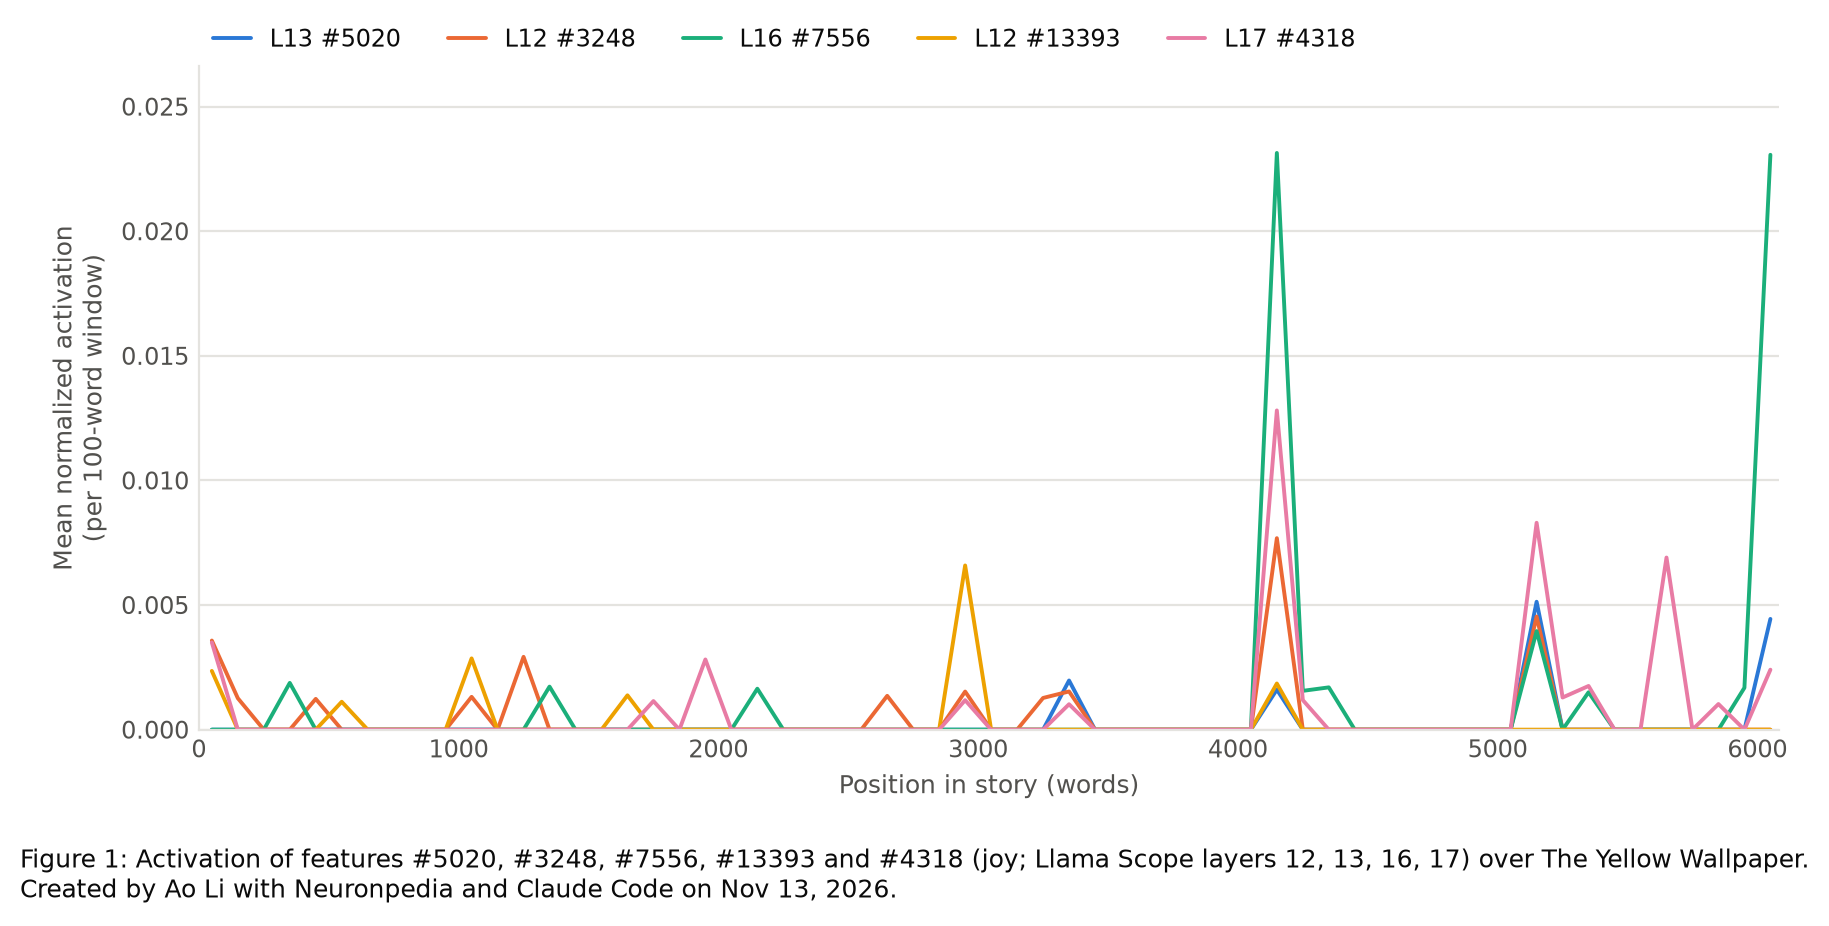

 window (words)   L13 #5020   L12 #3248   L16 #7556  L12 #13393   L17 #4318
    4100-4200        0.0016      0.0077      0.0231      0.0019      0.0128
    6000-6085        0.0044      0.0000      0.0231      0.0000      0.0024
    5100-5200        0.0051      0.0045      0.0040      0.0000      0.0083
       0-100         0.0000      0.0036      0.0000      0.0024      0.0035
    2900-3000        0.0000      0.0015      0.0000      0.0066      0.0012
    5600-5700        0.0000      0.0000      0.0000      0.0000      0.0069
    3300-3400        0.0020      0.0015      0.0000      0.0000      0.0010
    1000-1100        0.0000      0.0013      0.0000      0.0029      0.0000


In [5]:
ids = ", ".join(f"#{f[1]}" for f in FEATURES[:-1]) + f" and #{FEATURES[-1][1]}"
layers_used = ", ".join(sorted({f[0].split('-')[0] for f in FEATURES}, key=int))

fig, ax = plt.subplots(figsize=(9, 4.2), dpi=200)
for f, color in zip(FEATURES, SERIES):
    ax.plot(mids, arcs[f], color=color, linewidth=1.4, solid_joinstyle="round", solid_capstyle="round", label=short(f))
style_axes(ax, len(words), f"Mean normalized activation\n(per {WINDOW_WORDS}-word window)")
ax.set_ylim(0, max(max(a) for a in arcs.values()) * 1.15 or 1)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=N_FEATURES, frameon=False, fontsize=8.5,
          labelcolor=INK, handlelength=1.6, borderaxespad=0.2)
finish(fig,
       f"Figure 1: Activation of features {ids} ({EMOTION}; Llama Scope layers {layers_used}) over {STORY_NAME}. "
       f"Created by Ao Li with Neuronpedia and Claude Code on {FIG_DATE}.",
       Path("outputs/figures/pilot2/figure1.png"))

# Table view of the same data (the lighter line colours need it).
print(f"{'window (words)':>15} " + " ".join(f"{short(f):>11}" for f in FEATURES))
for w in sorted(range(len(mids)), key=lambda w: -sum(arcs[f][w] for f in FEATURES))[:8]:
    print(f"{w * WINDOW_WORDS:>8}-{min((w + 1) * WINDOW_WORDS, len(words)):<6} " + " ".join(f"{arcs[f][w]:>11.4f}" for f in FEATURES))

## Figure 2: the five added up as one emotion

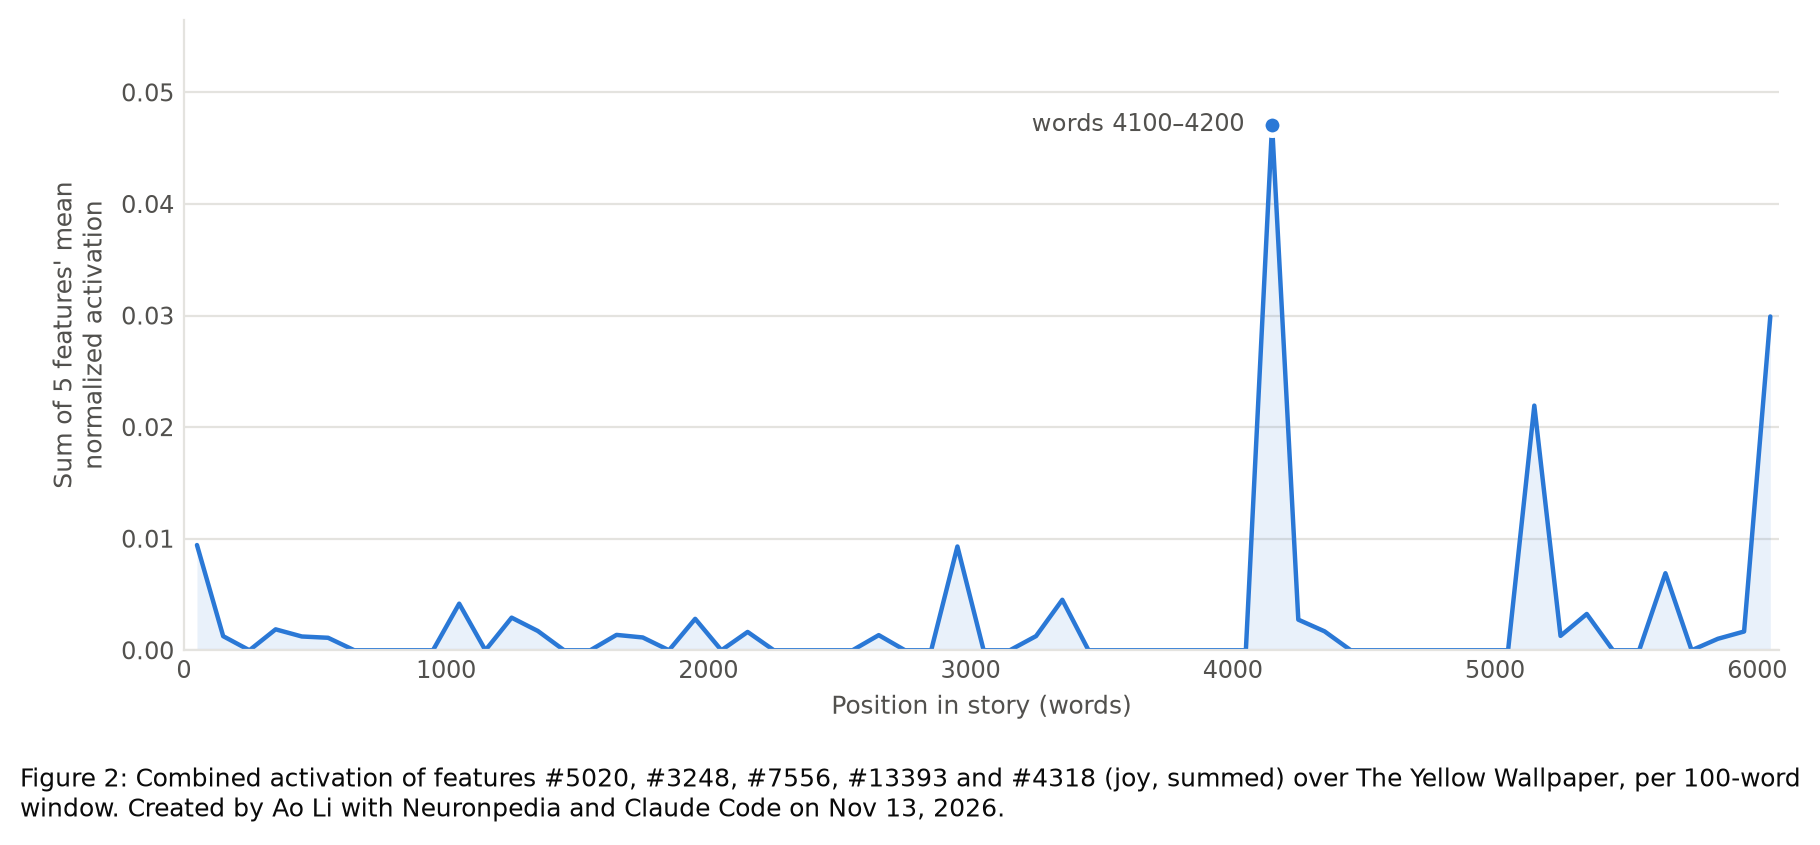

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.8), dpi=200)
ax.fill_between(mids, combined, color=SAE_COLOR, alpha=0.10, linewidth=0)
ax.plot(mids, combined, color=SAE_COLOR, linewidth=1.6, solid_joinstyle="round", solid_capstyle="round")
peak = combined.index(max(combined))
ax.plot(mids[peak], combined[peak], "o", markersize=7, color=SAE_COLOR, markeredgecolor="white", markeredgewidth=2, zorder=3)
ax.annotate(f"words {peak * WINDOW_WORDS}–{min((peak + 1) * WINDOW_WORDS, len(words))}", (mids[peak], combined[peak]),
            xytext=(-10 if mids[peak] > len(words) / 2 else 10, 0), textcoords="offset points",
            ha="right" if mids[peak] > len(words) / 2 else "left", va="center", fontsize=8.5, color=MUTED)
style_axes(ax, len(words), f"Sum of {N_FEATURES} features' mean\nnormalized activation")
ax.set_ylim(0, max(combined) * 1.2 or 1)
finish(fig,
       f"Figure 2: Combined activation of features {ids} ({EMOTION}, summed) over {STORY_NAME}, "
       f"per {WINDOW_WORDS}-word window. Created by Ao Li with Neuronpedia and Claude Code on {FIG_DATE}.",
       Path("outputs/figures/pilot2/figure2.png"))

## Figure 3: compared with EmoLex

The two measures are on different scales, so they get a panel each over the same x-axis instead of two y-axes on one plot. Figure 4 puts them on one axis after normalizing.

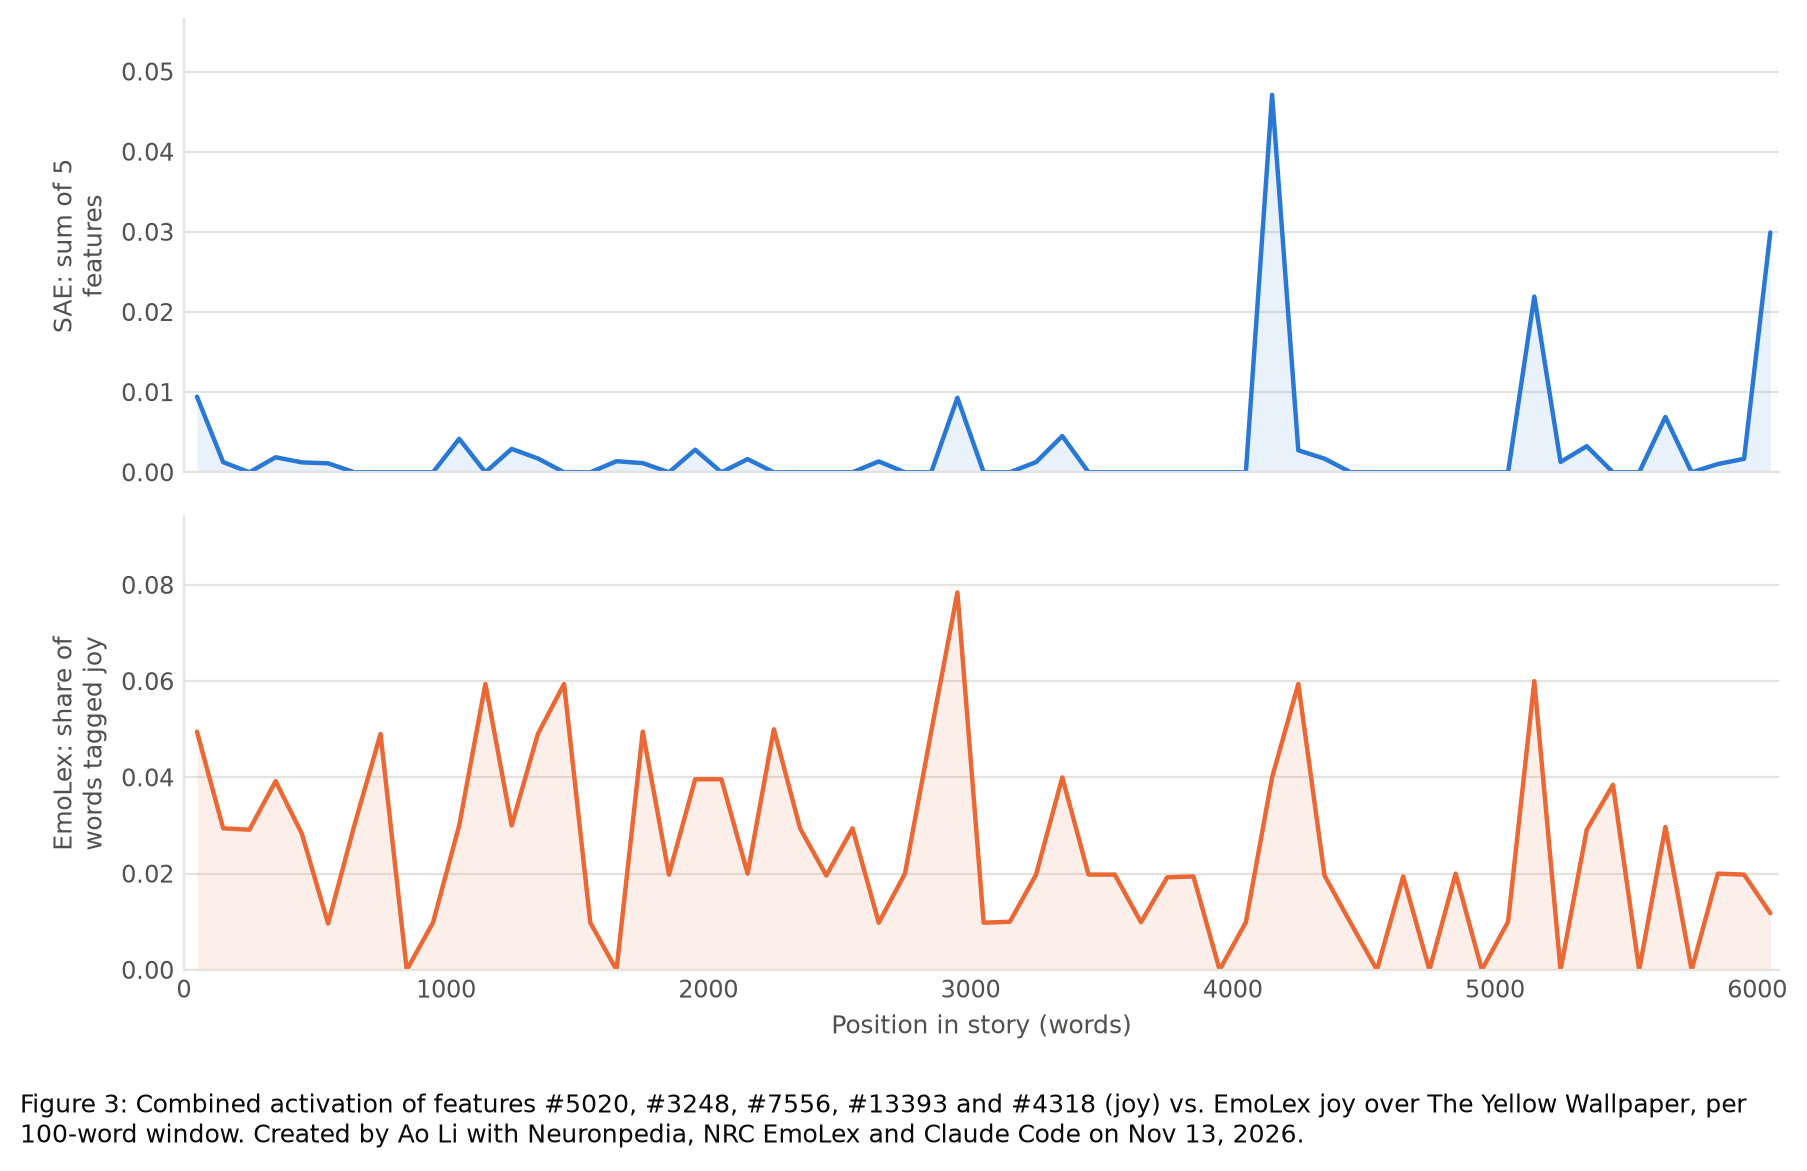

In [7]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.4), dpi=200, sharex=True)
for ax, values, color, ylabel in (
    (top, combined, SAE_COLOR, f"SAE: sum of {N_FEATURES}\nfeatures"),
    (bottom, emolex, EMOLEX_COLOR, f"EmoLex: share of\nwords tagged {EMOTION}"),
):
    ax.fill_between(mids, values, color=color, alpha=0.10, linewidth=0)
    ax.plot(mids, values, color=color, linewidth=1.6, solid_joinstyle="round", solid_capstyle="round")
    style_axes(ax, len(words), ylabel)
    ax.set_ylim(0, max(values) * 1.2 or 1)
top.set_xlabel("")
finish(fig,
       f"Figure 3: Combined activation of features {ids} ({EMOTION}) vs. EmoLex {EMOTION} over {STORY_NAME}, "
       f"per {WINDOW_WORDS}-word window. Created by Ao Li with Neuronpedia, NRC EmoLex and Claude Code on {FIG_DATE}.",
       Path("outputs/figures/pilot2/figure3.png"))

## Figure 4: both on one graph, each min-max normalized to [0, 1]

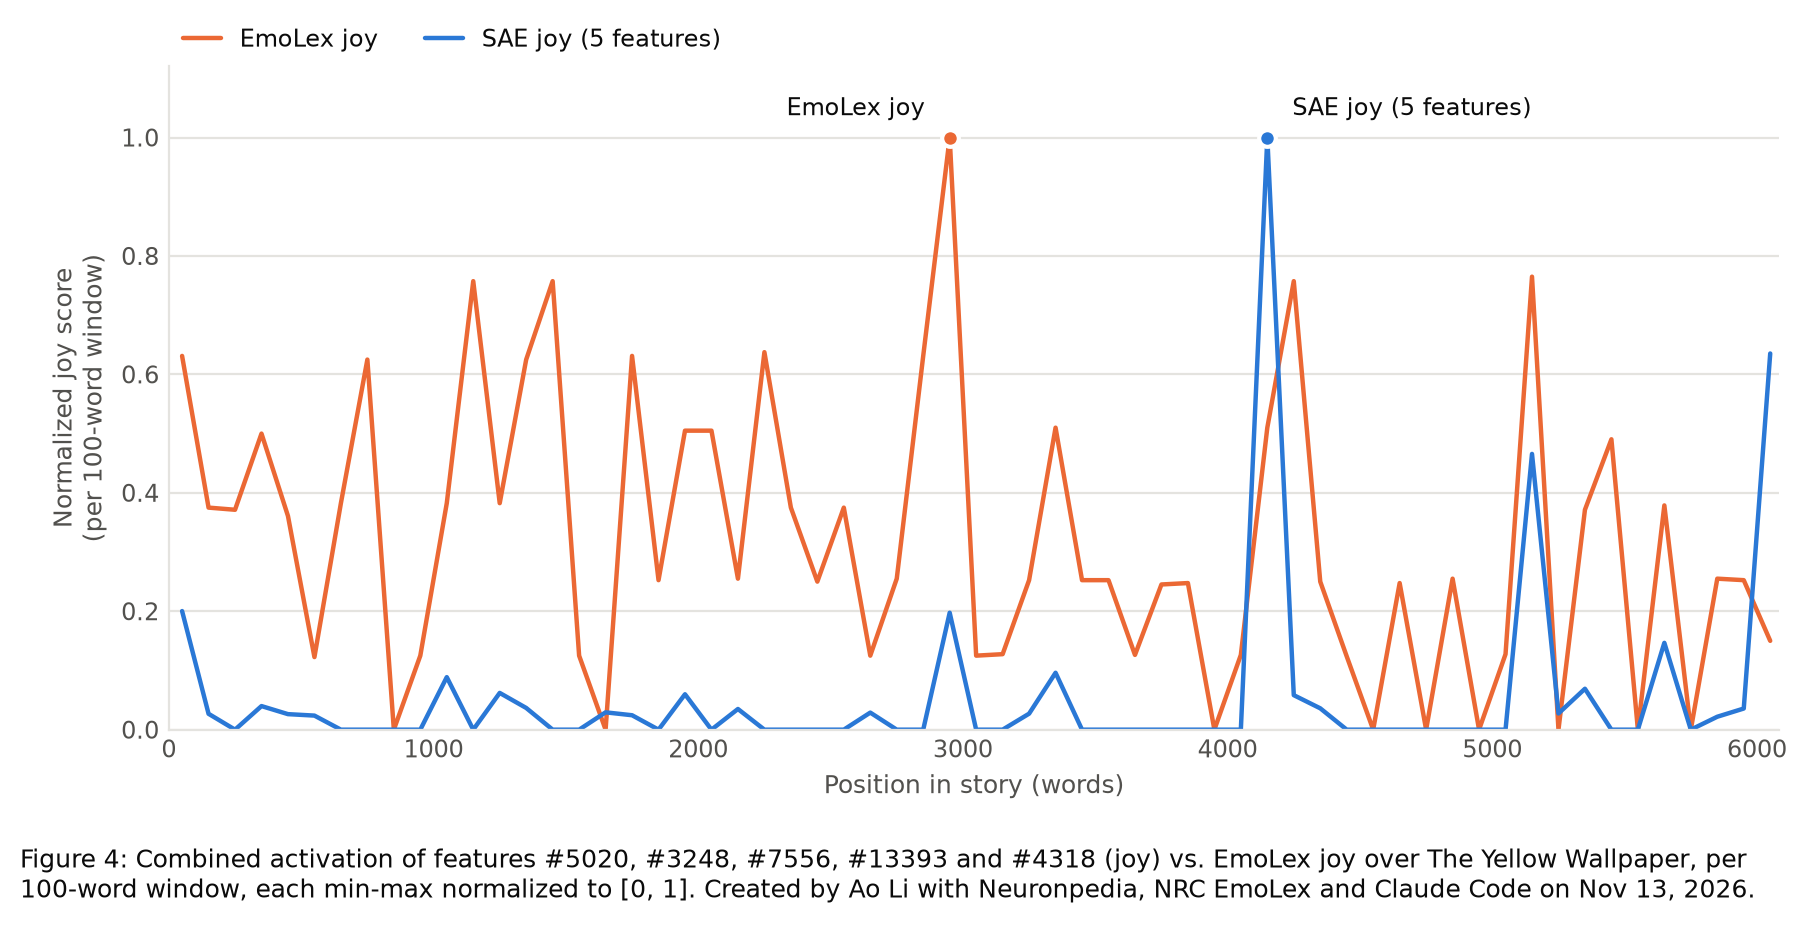

61 windows; SAE nonzero in 26, EmoLex in 52, both in 24
Pearson r = 0.24


In [8]:
def plot_both(sae_norm: list[float], emolex_norm: list[float], ylabel: str, caption: str, path: Path) -> None:
    """The SAE and EmoLex arcs on one axis, each labelled where it stands furthest above the other."""
    fig, ax = plt.subplots(figsize=(9, 4.2), dpi=200)
    series = [(f"EmoLex {EMOTION}", emolex_norm, EMOLEX_COLOR), (f"SAE {EMOTION} ({N_FEATURES} features)", sae_norm, SAE_COLOR)]
    for label, values, color in series:
        ax.plot(mids, values, color=color, linewidth=1.6, solid_joinstyle="round", solid_capstyle="round", label=label)
    # Direct labels where each line stands furthest above the other, each on the side away from the other
    # label, backed in white so lines pass behind them.
    spots = [max(range(len(values)), key=lambda i: values[i] - other[i]) for (_, values, _), (_, other, _) in zip(series, series[::-1])]
    for (label, values, color), w, other_w in zip(series, spots, spots[::-1]):
        ax.plot(mids[w], values[w], "o", markersize=6, color=color, markeredgecolor="white", markeredgewidth=1.5, zorder=3)
        left = mids[w] < mids[other_w] or (w == other_w and mids[w] > len(words) / 2)
        if not 0.15 * len(words) < mids[w] < 0.85 * len(words):
            left = mids[w] > len(words) / 2  # near an edge, put the label on the inside
        ax.annotate(label, (mids[w], values[w]), xytext=(-9 if left else 9, 6), textcoords="offset points",
                    ha="right" if left else "left", va="bottom", fontsize=8.5, color=INK, zorder=4,
                    bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none"))
    style_axes(ax, len(words), ylabel)
    ax.set_ylim(0, 1.12)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=8.5, labelcolor=INK,
              handlelength=1.6, borderaxespad=0.2)
    finish(fig, caption, path)


sae_norm, emolex_norm = normalize(combined), normalize(emolex)
plot_both(
    sae_norm, emolex_norm, f"Normalized {EMOTION} score\n(per {WINDOW_WORDS}-word window)",
    f"Figure 4: Combined activation of features {ids} ({EMOTION}) vs. EmoLex {EMOTION} over {STORY_NAME}, "
    f"per {WINDOW_WORDS}-word window, each min-max normalized to [0, 1]. "
    f"Created by Ao Li with Neuronpedia, NRC EmoLex and Claude Code on {FIG_DATE}.",
    Path("outputs/figures/pilot2/figure4.png"),
)

both = sum(a > 0 and b > 0 for a, b in zip(sae_norm, emolex_norm))
print(f"{len(mids)} windows; SAE nonzero in {sum(v > 0 for v in sae_norm)}, EmoLex in {sum(v > 0 for v in emolex_norm)}, both in {both}")
print(f"Pearson r = {pearson(sae_norm, emolex_norm):.2f}")

## Figure 5: both on one graph, each log-normalized to [0, 1]

Figure 4 with the extremes curbed: each series is divided by its median nonzero window, passed through log(1 + x), then min-max scaled to [0, 1] (`log_normalize`). One spiky window no longer flattens the rest of the arc, so the quieter stretches of the story become readable. Windows where a measure is 0 stay at 0.

In [ ]:
sae_log, emolex_log = log_normalize(combined), log_normalize(emolex)
plot_both(
    sae_log, emolex_log, f"Log-normalized {EMOTION} score\n(per {WINDOW_WORDS}-word window)",
    f"Figure 5: Combined activation of features {ids} ({EMOTION}) vs. EmoLex {EMOTION} over {STORY_NAME}, "
    f"per {WINDOW_WORDS}-word window, each log-normalized to [0, 1]. "
    f"Created by Ao Li with Neuronpedia, NRC EmoLex and Claude Code on {FIG_DATE}.",
    Path("outputs/figures/pilot2/figure5.png"),
)

print(f"Pearson r = {pearson(sae_log, emolex_log):.2f} (min-max, Figure 4: {pearson(sae_norm, emolex_norm):.2f})")